# Parkinson's Detection from Voice Measurements

**Dataset:** UCI Parkinsons — 195 voice recordings from 31 people (23 with Parkinson's), each summarised into 22 acoustic measurements (pitch variation, jitter, shimmer, noise ratios…). **Task:** classify healthy vs Parkinson's from the voice features.

⚠️ **Read the caveat before the score:** 195 recordings but only 31 *people* — recordings from the same person appear in both train and test, so the accuracy is optimistic versus testing on entirely new patients. A research demo, not a diagnostic tool.

In [1]:
import io, urllib.request, zipfile
import pandas as pd

def get(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=90) as r: return r.read()

zf = zipfile.ZipFile(io.BytesIO(get('https://archive.ics.uci.edu/static/public/174/parkinsons.zip')))
name = [n for n in zf.namelist() if n.endswith('.data')][0]
d = pd.read_csv(io.BytesIO(zf.read(name)))
print(d.shape, '| Parkinson recordings:', int(d['status'].sum()))
d.head()

(195, 24) | Parkinson recordings: 147


,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


Logistic Regression accuracy: 0.9388
Random Forest accuracy: 0.9184
              precision    recall  f1-score   support

     Healthy       0.91      0.83      0.87        12
 Parkinson's       0.95      0.97      0.96        37

    accuracy                           0.94        49
   macro avg       0.93      0.90      0.91        49
weighted avg       0.94      0.94      0.94        49



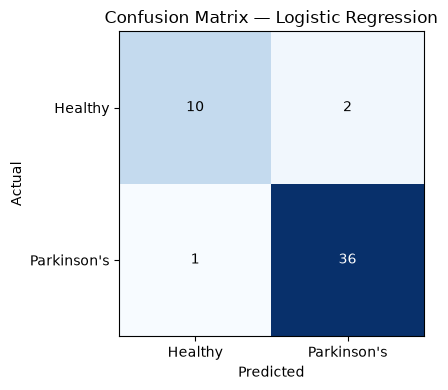

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

y = d['status']; X = d.drop(columns=['name', 'status'])
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
sc = StandardScaler().fit(Xtr)
lr = LogisticRegression(max_iter=1000).fit(sc.transform(Xtr), ytr)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
pred = lr.predict(sc.transform(Xte))
print('Logistic Regression accuracy:', round(accuracy_score(yte, pred), 4))
print('Random Forest accuracy:', round(accuracy_score(yte, rf.predict(Xte)), 4))
print(classification_report(yte, pred, target_names=['Healthy', "Parkinson's"]))
cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1], ['Healthy', "Parkinson's"]); ax.set_yticks([0, 1], ['Healthy', "Parkinson's"])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion Matrix — Logistic Regression')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
fig.tight_layout(); fig.savefig('confusion_matrix.png', dpi=110); plt.show()

## What I learned
- Voice really does carry signal: pitch instability measures (jitter/shimmer family) separate the classes well.
- The dataset's weakness is structural: multiple recordings per person + a random split = the model partly recognises *people*, not just disease. A subject-wise split is the honest follow-up and would score lower.
- Small-n medical datasets demand humility: 31 people cannot validate a screening tool.